# 07 — Figure 1: SST anomaly decomposition

FULL (top), UNIFORM (middle) and PATTERN (bottom) SST anomaly for the
strongest El Niño (1983, left) and La Niña (1989, right), as written by `02`.

The figure is drawn at its printed width (`FIG_WIDTH`, 7 in), so the font
sizes below are the sizes in the journal. Output: `figures/fig1_sst_decomp.png`
(300 dpi) and `.pdf` (vector, editable text).

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.mpl.ticker import LatitudeFormatter

plt.rcParams.update({
    "font.size": 8, "font.family": "sans-serif",
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
FIG_WIDTH = 7.0   # inches, full page width in print

EL_NINO_YEAR = 1983
LA_NINA_YEAR = 1989

## Step 1 — load the FULL / UNIFORM / PATTERN fields

In [2]:
def event_dir(event_type):
    return cfg.DATA_AMIP_ELNINO_DIR if event_type == "El Niño" else cfg.DATA_AMIP_LANINA_DIR


def load_fields(year, event_type):
    d = event_dir(event_type)
    full = xr.open_dataset(os.path.join(d, f"{year}_FULL.nc"))["sst_anomaly_tapered"]
    uniform = xr.open_dataset(os.path.join(d, f"{year}_UNIFORM.nc"))["uniform_warming"]
    pattern = xr.open_dataset(os.path.join(d, f"{year}_PATTERN.nc"))["sst_residual"]
    return [full, uniform, pattern]   # top-to-bottom order of the figure


el_nino_fields = load_fields(EL_NINO_YEAR, "El Niño")
la_nina_fields = load_fields(LA_NINA_YEAR, "La Niña")
all_fields = el_nino_fields + la_nina_fields
print(f"plotted range: {float(min(f.min() for f in all_fields)):.2f} to {float(max(f.max() for f in all_fields)):.2f} °C")
LON_FIRST, LON_LAST = float(all_fields[0].lon[0]), float(all_fields[0].lon[-1])
print(f"longitude axis: {LON_FIRST} to {LON_LAST} °E ({all_fields[0].lon.size} points)")

plotted range: -2.06 to 3.75 °C
longitude axis: 0.0 to 359.0 °E (360 points)


## Step 2 — draw the 3 × 2 grid

Values beyond ±3 °C are drawn in the end colours and marked by the small
triangles at the ends of the colour bar (`extend="both"`); without `extend`,
contourf leaves those cells blank.

Each map spans the whole grid in longitude, first to last grid point; the last
point is labelled 0° so the band reads as one full circle.

saved figures/fig1_sst_decomp.png
saved figures/fig1_sst_decomp.pdf


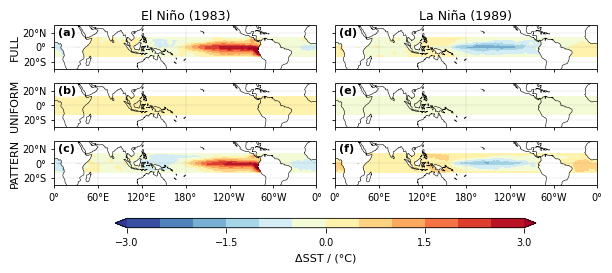

In [3]:
row_names = ["FULL", "UNIFORM", "PATTERN"]
columns = [(EL_NINO_YEAR, "El Niño", el_nino_fields), (LA_NINA_YEAR, "La Niña", la_nina_fields)]
panel_letters = [["a", "d"], ["b", "e"], ["c", "f"]]   # [row][col]

VMIN, VMAX = -3, 3
N_LEVELS = 13            # shading boundaries (12 bands)
N_TICKS = 5              # colour bar labels: -3, -1.5, 0, 1.5, 3
SHOW_LON_LABELS = True   # <- False hides the longitude labels and meridians
LON_LABELS = ["0°", "60°E", "120°E", "180°", "120°W", "60°W", "0°"]   # last one sits on the last grid point
LON_TICKS = [LON_FIRST, 60, 120, 180, 240, 300, LON_LAST]
LAT_MAX = 30
LAT_TICKS = [-20, 0, 20]     # ±30° would collide between the tightly stacked rows
levels = np.linspace(VMIN, VMAX, N_LEVELS)
cbar_ticks = np.linspace(VMIN, VMAX, N_TICKS)

# map projection centred on 180°: x = lon - 180, so the grid runs left to right without a break
PROJ = ccrs.PlateCarree(central_longitude=180)
to_x = lambda lon: lon - 180

fig, axes = plt.subplots(3, 2, figsize=(FIG_WIDTH, 2.7),
                         subplot_kw={"projection": PROJ},
                         gridspec_kw={"wspace": 0.07, "hspace": 0.18})

mesh = None
for col, (year, event_type, fields) in enumerate(columns):
    axes[0, col].set_title(f"{event_type} ({year})", fontsize=9, pad=4)
    for row, (field, row_name) in enumerate(zip(fields, row_names)):
        ax = axes[row, col]
        # lock the view first: otherwise the next plotting call autoscales the
        # map back to the data's bounding box and ignores set_extent
        ax.set_autoscale_on(False)
        ax.set_extent([to_x(LON_FIRST), to_x(LON_LAST), -LAT_MAX, LAT_MAX], crs=PROJ)
        ax.coastlines(linewidth=0.4)

        # plain axis ticks rather than gridliner labels: drawn on every frame, labelled on the outer ones
        ax.set_xticks([to_x(lon) for lon in LON_TICKS], crs=PROJ)
        ax.set_xticklabels(LON_LABELS)
        ax.set_yticks(LAT_TICKS, crs=ccrs.PlateCarree())
        ax.yaxis.set_major_formatter(LatitudeFormatter())
        ax.tick_params(length=2, labelsize=7, labelleft=(col == 0),
                       labelbottom=(row == 2) and SHOW_LON_LABELS)
        ax.gridlines(draw_labels=False, xlocs=LON_TICKS[1:-1] if SHOW_LON_LABELS else [], ylocs=LAT_TICKS,
                     linewidth=0.2, color="gray", alpha=0.5)

        mesh = ax.contourf(field.lon, field.lat, field.values, levels=levels, cmap="RdYlBu_r",
                           extend="both", transform=ccrs.PlateCarree())
        ax.text(0.015, 0.94, f"({panel_letters[row][col]})", transform=ax.transAxes, fontsize=8,
                fontweight="bold", va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.8))
        if col == 0:
            ax.text(-0.15, 0.5, row_name, transform=ax.transAxes, rotation=90,
                    va="center", ha="center", fontsize=8)

cbar = fig.colorbar(mesh, ax=axes, orientation="horizontal", fraction=0.045, pad=0.16, aspect=45,
                    ticks=cbar_ticks, extendfrac=0.03)
cbar.set_label("ΔSST / (°C)", fontsize=8)   # "ΔSST / (°C)"
cbar.ax.tick_params(labelsize=7, width=0.6)

os.makedirs(cfg.FIGURES_DIR, exist_ok=True)
for ext in ["png", "pdf"]:
    out_path = os.path.join(cfg.FIGURES_DIR, f"fig1_sst_decomp.{ext}")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print("saved", os.path.relpath(out_path, cfg.REPO_ROOT))
plt.show()